In [9]:
from typing import TypedDict , List
from langgraph.graph import StateGraph , START , END

In [10]:
class AgentState(TypedDict):
    num_1 : int
    opr : str
    num_2 : int
    res : int
    

In [11]:
def adder(state : AgentState) -> AgentState :
    """ this will add numbers """
    state['res'] = state['num_1'] + state['num_2']
    return state


def sub(state : AgentState) -> AgentState :
    """ this will subtract numbers """
    state['res'] = state['num_1'] - state['num_2']
    return state

def decide(state : AgentState):
    if state['opr'] == "+":
        return "addition"
    if state['opr'] == '-':
        return "subtraction"
    

In [12]:
graph = StateGraph(AgentState)

graph.add_node('adder', adder)
graph.add_node('sub',sub)
graph.add_node('router', lambda state : state)

graph.add_edge(START , 'router')
graph.add_conditional_edges(
    'router',decide,
    {
        'addition':'adder',
        'subtraction':'sub'
    }
)
graph.add_edge('adder' , END)
graph.add_edge('sub', END)

app = graph.compile()

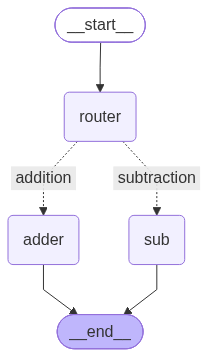

In [13]:
app

In [14]:
res = app.invoke({
    'num_1' :1,
    'opr' :"+",
    'num_2' :2,
    'res':0
})

res['res']

3

____

In [15]:
class AgentState(TypedDict):
    num_1 : int
    opr_1 : str
    num_2 : int
    res_1 : int
    num_3 : int
    opr_2 : str
    num_4 : int
    res_2 : int    
    

In [16]:
def adder_1(state : AgentState) -> AgentState :
    """ this will add numbers """
    state['res_1'] = state['num_1'] + state['num_2']
    return state


def sub_1(state : AgentState) -> AgentState :
    """ this will subtract numbers """
    state['res_1'] = state['num_1'] - state['num_2']
    return state

def decide_1(state : AgentState):
    """This node will select the next phase"""
    if state['opr_1'] == "+":
        return "addition"
    if state['opr_1'] == '-':
        return "subtraction"
    
def adder_2(state : AgentState) -> AgentState :
    """ this will add numbers """
    state['res_2'] = state['num_3'] + state['num_4']
    return state


def sub_2(state : AgentState) -> AgentState :
    """ this will subtract numbers """
    state['res_2'] = state['num_3'] - state['num_4']
    return state

def decide_2(state : AgentState):
    """This node will select the next phase"""
    if state['opr_2'] == "+":
        return "addition"
    if state['opr_2'] == '-':
        return "subtraction"


In [17]:
graph = StateGraph(AgentState)

graph.add_edge(START,'router_1')

graph.add_node('adder_1', adder_1)
graph.add_node('sub_1',sub_1)
graph.add_node('router_1', lambda state : state)

graph.add_node('adder_2',adder_2)
graph.add_node('sub_2',sub_2)
graph.add_node('router_2', lambda state : state)


graph.add_conditional_edges(
    'router_1', decide_1,{
        'addition':'adder_1',
        'subtraction':'sub_1'
    }
)

graph.add_edge('adder_1', 'router_2')
graph.add_edge('sub_1', 'router_2')

graph.add_conditional_edges(
    'router_2', decide_2,{
        'addition':'adder_2',
        'subtraction':'sub_2'
    }
)


graph.add_edge('adder_2', END)
graph.add_edge('sub_2', END)

app = graph.compile()

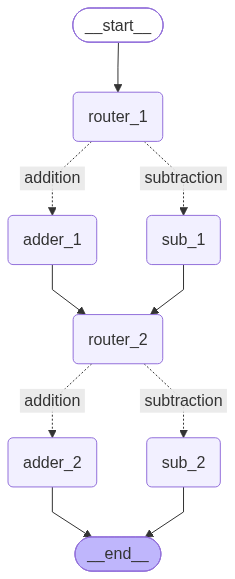

In [18]:
app

In [19]:
app.invoke({
    'num_1' : 1,
    'opr_1' : '+',
    'num_2' : 2,
    'num_3' : 2,
    'opr_2' : '-',
    
    'num_4' : 2,
}) # ignore

{'num_1': 1,
 'opr_1': '+',
 'num_2': 2,
 'res_1': 3,
 'num_3': 2,
 'opr_2': '-',
 'num_4': 2,
 'res_2': 0}